<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/PMC_VQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PMC-VQA Dataset Analysis

This notebook analyzes the PMC-VQA (PubMed Central Visual Question Answering) dataset for the doctoral research project (Paper 2).

## Dataset Overview
PMC-VQA is a dataset of medical visual question answering with multiple choice questions where only one answer is correct.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from collections import Counter
import re

# Download required NLTK data
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# Visualization configuration
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
from google.colab import files
import pandas as pd
import io

# Select and load the CSV file from the computer
uploaded_files = files.upload()

# Get the name of the uploaded file
file_name = next(iter(uploaded_files))

# Read the CSV file and convert it to a DataFrame
df = pd.read_csv(
    io.BytesIO(uploaded_files[file_name])
)

# Display the first rows
display(df.head())

# Display general information
print(f'Loaded file: {file_name}')
print(f'Number of rows: {df.shape[0]}')
print(f'Number of columns: {df.shape[1]}')
print('\nColumns:')
print(df.columns.tolist())

Saving pmc-vqa.csv to pmc-vqa.csv


,index,Figure_path,Caption,Question,Choice A,Choice B,Choice C,Choice D,Answer,split,ground_truth
0,35,PMC8253797_Fig4_11.jpg,A slightly altered cell . (c-c‴) A highly alte...,What color is used to label the Golgi complex...,A: Green,B: Red,C: Light blue,D: Yellow,B,train,Red
1,39,PMC8253797_Fig4_14.jpg,A slightly altered cell . (c-c‴) A highly alte...,Which color represents the cell outline in the...,A: Green,B: Yellow,C: Light blue,D: Red,B,train,Yellow
2,41,PMC8253797_Fig4_15.jpg,A slightly altered cell . (c-c‴) A highly alte...,What is labeled in red in the image?,A:Golgi complexes,B:Cell nuclei,C:Lysosomes,D:Mitochondria/mitochondrial networks,A,train,Golgi complexes
3,62,PMC8253867_Fig2_41.jpg,CT pulmonary angiogram reveals encasement and ...,What is the name of the artery encased and di...,A: Right Coronary Artery,B: Left Anterior Descending Coronary Artery,C: Circumflex Coronary Artery,D: Superior Mesenteric Artery,B,test,Left Anterior Descending Coronary Artery
4,65,PMC8253867_Fig2_42.jpg,CT pulmonary angiogram reveals encasement and ...,Which artery is encased and displaced accordi...,A:Left main coronary artery,B:Circumflex artery,C:Right coronary artery,D:Left anterior descending coronary artery.,D,test,Left anterior descending coronary artery.


Loaded file: pmc-vqa.csv
Number of rows: 186033
Number of columns: 11

Columns:
['index', 'Figure_path', 'Caption', 'Question', 'Choice A', 'Choice B', 'Choice C', 'Choice D', 'Answer', 'split', 'ground_truth']


## 2. Load and Explore the Data

In [3]:
variables = [
    'index',
    'Caption',
    'Question',
    'Choice A',
    'Choice B',
    'Choice C',
    'Choice D',
    'Answer',
    'ground_truth'
]

print("Allowed variables in PMC-VQA:")
for var in variables:
    print(f"  - {var}")

Allowed variables in PMC-VQA:
  - index
  - Caption
  - Question
  - Choice A
  - Choice B
  - Choice C
  - Choice D
  - Answer
  - ground_truth


In [4]:
# Calculate the length of questions, answers, and captions
df['question_length'] = df['Question'].str.len()
df['answer_length'] = df['ground_truth'].str.len()
df['caption_length'] = df['Caption'].str.len()

# Calculate word length using NLTK
def count_nltk_words(text: str) -> int:
    """Count the words in text using NLTK.

    Args:
        text: The text to analyze.

    Returns:
        The number of non-whitespace words.
    """
    if not isinstance(text, str) or not text.strip():
        return 0
    tokens = word_tokenize(text.lower())
    # Filter tokens that are only whitespace or empty
    words = [token for token in tokens if token.strip()]
    return len(words)

df['question_words'] = df['Question'].apply(count_nltk_words)
df['answer_words'] = df['ground_truth'].apply(count_nltk_words)
df['caption_words'] = df['Caption'].apply(count_nltk_words)

# Calculate the length of the answer choices
for choice in ['Choice A', 'Choice B', 'Choice C', 'Choice D']:
    df[f'{choice}_length'] = df[choice].str.len()
    df[f'{choice}_words'] = df[choice].apply(count_nltk_words)

print("Length columns created successfully")
print(f"  - question_length (characters)")
print(f"  - answer_length (characters)")
print(f"  - caption_length (characters)")
print(f"  - question_words (words - NLTK)")
print(f"  - answer_words (words - NLTK)")
print(f"  - caption_words (words - NLTK)")

Length columns created successfully
  - question_length (characters)
  - answer_length (characters)
  - caption_length (characters)
  - question_words (words - NLTK)
  - answer_words (words - NLTK)
  - caption_words (words - NLTK)


In [5]:
# Pattern for identifying radiological content
radiological_pattern = re.compile(
    r'\b('
    r'mri|mr|magnetic resonance|'
    r'ct|cat scan|computed tomography|computerized tomography|'
    r'x[\s-]?ray|radiograph|radiography|'
    r'pet|positron emission|spect|'
    r'ultrasound|sonograph|sonogram|echograph|echocardiograph|'
    r'fluoroscop|mammograph|mammogram|'
    r'angiograph|angiogram|scintigraph|'
    r'dexa|dxa|bone densitometry|nuclear medicine|'
    r't1[\s-]?weighted|t2[\s-]?weighted|t1w|t2w|'
    r't1|t2|flair|dwi|dti|adc|bold|'
    r'gadolinium|contrast[\s-]?enhanced|'
    r'hounsfield|hrct|'
    r'hyperintens|hypointens|isointens|'
    r'hyperdense|hypodense|isodense|'
    r'radiolucen|radiopaque|attenuati|enhancement|'
    r'axial|coronal|sagittal|transaxial|'
    r'opacity|consolidation|ground[\s-]?glass|'
    r'atelectasis|pneumothorax|pleural effusion|'
    r'pericardial effusion|calcification|sclerosis|'
    r'stenosis|occlusion|embolism|thrombosis|'
    r'infarct|ischemi|radiolog|medical imaging|'
    r'diagnostic imaging|imaging study|scan|scanner|image|imaging'
    r')\b',
    flags=re.IGNORECASE
)

# Function for classifying each row
def is_radiological(row):
    """Classify a row by its caption, question, and answer text.

    Args:
        row: The row containing the text fields to classify.

    Returns:
        The radiological-content category for the row.
    """

    caption = str(row.get('Caption', ''))
    question = str(row.get('Question', ''))
    answer = str(row.get('ground_truth', ''))

    full_text = f'{caption} {question} {answer}'

    if radiological_pattern.search(full_text):
        return 'Radiological Content'
    else:
        return 'Other'

# Create the required column
df['content_type'] = df.apply(is_radiological, axis=1)

# Check the result
print(df['content_type'].value_counts())

content_type
Radiological Content    132815
Other                    53218
Name: count, dtype: int64


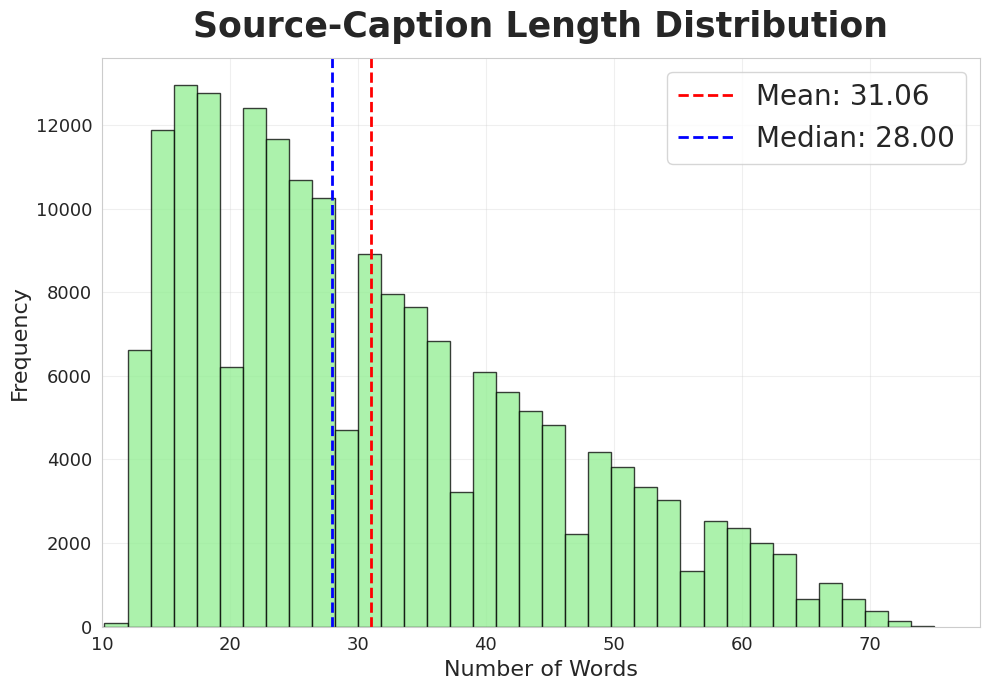

In [6]:
# ============================================================
# FIGURE 1: SOURCE
# CAPTION LENGH DISTRIBUTION
# ============================================================

# Calculate the number of words if the column does not yet exist
if 'caption_words' not in df.columns:
    df['caption_words'] = (
        df['Caption']
        .fillna('')
        .astype(str)
        .str.split()
        .str.len()
    )

mean = df['caption_words'].mean()
median = df['caption_words'].median()

fig, ax = plt.subplots(figsize=(10, 7))

ax.hist(
    df['caption_words'],
    bins=40,
    color='lightgreen',
    edgecolor='black',
    alpha=0.75
)

ax.axvline(
    mean,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean: {mean:.2f}'
)

ax.axvline(
    median,
    color='blue',
    linestyle='--',
    linewidth=2,
    label=f'Median: {median:.2f}'
)

ax.set_xlabel('Number of Words', fontsize=16)
ax.set_ylabel('Frequency', fontsize=16)

ax.set_title(
    'Source-Caption Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=15
)

ax.tick_params(axis='both', labelsize=13)
ax.legend(fontsize=20)
ax.grid(alpha=0.3)


# Start the X-axis at 10 words
ax.set_xlim(left=10)

plt.tight_layout()
plt.show()

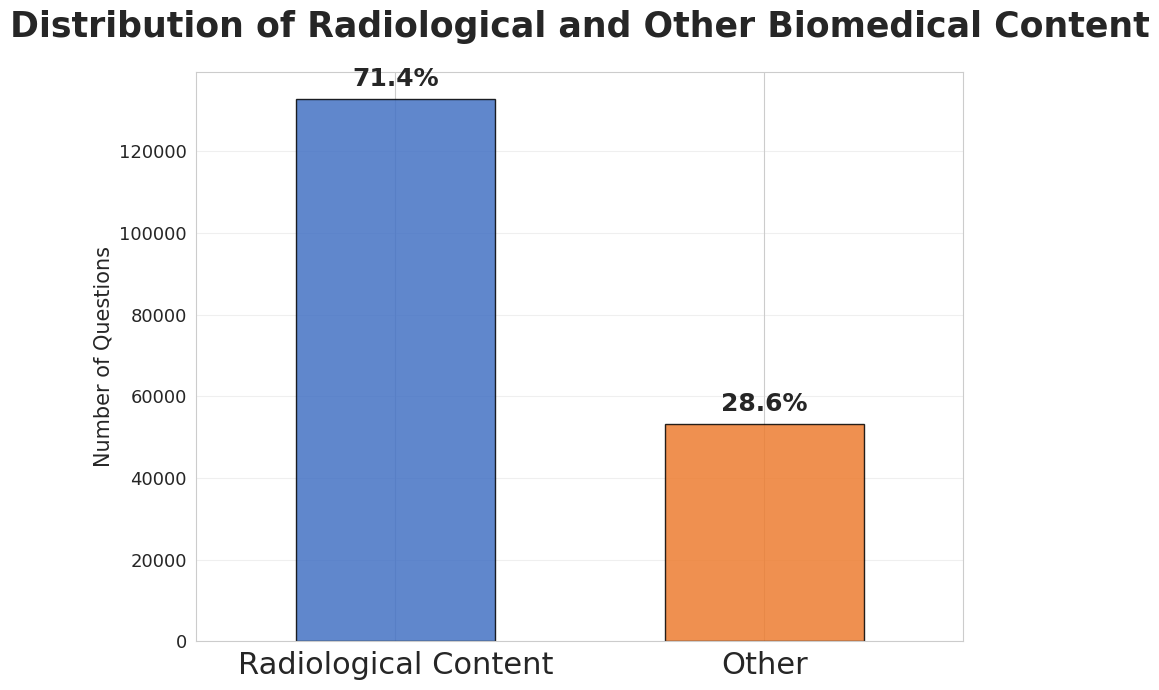

In [7]:
# ============================================================
# FIGURE 2: DISTRIBUTION OF
# RADIOLOGICAL AND OTHER CONTENT
# ============================================================

content_counts = df['content_type'].value_counts()

radiological_count = content_counts.get('Radiological Content', 0)
other_count = content_counts.get('Other', 0)
total = radiological_count + other_count

labels = ['Radiological Content', 'Other']
values = [radiological_count, other_count]
colors = ['#4472C4', '#ED7D31']

fig, ax = plt.subplots(figsize=(9, 7))

# Closer positions for the bars
positions = [0, 0.65]

bars = ax.bar(
    positions,
    values,
    width=0.35,
    color=colors,
    alpha=0.85,
    edgecolor='black',
    linewidth=1
)

# Place the labels below the bars
ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=25)

# Reduce empty space at the ends
ax.set_xlim(-0.35, 1.0)

ax.set_ylabel('Number of Questions', fontsize=15)

ax.set_title(
    'Distribution of Radiological and Other Biomedical Content',
    fontsize=25,
    fontweight='bold',
    pad=25
)

ax.tick_params(axis='x', labelsize=22)
ax.tick_params(axis='y', labelsize=13)
ax.grid(axis='y', alpha=0.3)

offset = max(values) * 0.015

for bar, value in zip(bars, values):
    percentage = value / total * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + offset,
        f'{percentage:.1f}%',
        ha='center',
        va='bottom',
        fontsize=18,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

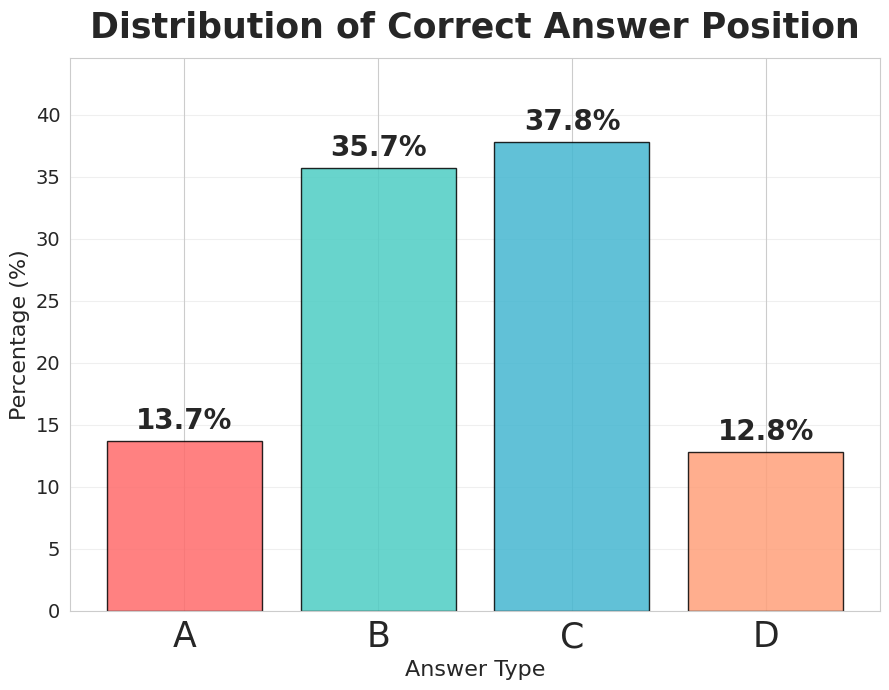

In [8]:
# ============================================================
# FIGURE 3: DISTRIBUTION OF
# CORRECT ASNWER POSITION
# ============================================================

def normalize_answer(value):
    """Normalize an answer label to A, B, C, D, or Other.

    Args:
        value: The answer label to normalize.

    Returns:
        The normalized answer label.
    """
    if not isinstance(value, str):
        return 'Other'

    value = value.strip().upper()

    equivalences = {
        'A': 'A',
        'B': 'B',
        'C': 'C',
        'D': 'D',
        'CHOICE A': 'A',
        'CHOICE B': 'B',
        'CHOICE C': 'C',
        'CHOICE D': 'D',
        '0': 'A',
        '1': 'B',
        '2': 'C',
        '3': 'D'
    }

    return equivalences.get(value, 'Other')


answer_norm = df['Answer'].apply(normalize_answer)

answer_dist = (
    answer_norm[answer_norm != 'Other']
    .value_counts()
    .reindex(['A', 'B', 'C', 'D'], fill_value=0)
)

total_valid = answer_dist.sum()

# Calculate percentages, adjusting the last value to guarantee an exact 100% sum
raw_pcts = [v / total_valid * 100 for v in answer_dist.values]
rounded_pcts = [round(p, 1) for p in raw_pcts[:-1]]
rounded_pcts.append(round(100.0 - sum(rounded_pcts), 1))

#percentages = answer_dist / answer_dist.sum() * 100

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']

fig, ax = plt.subplots(figsize=(9, 7))

bars = ax.bar(
    answer_dist.index,
    rounded_pcts,
    color=colors,
    alpha=0.85,
    edgecolor='black',
    linewidth=1
)

ax.set_xlabel('Answer Type', fontsize=16)
ax.set_ylabel('Percentage (%)', fontsize=16)

ax.set_title(
    'Distribution of Correct Answer Position',
    fontsize=25,
    fontweight='bold',
    pad=15
)

ax.set_ylim(0, max(rounded_pcts) * 1.18)
# Size of A, B, C, and D
ax.tick_params(axis='x', labelsize=25)

# Size of the vertical-axis numbers
ax.tick_params(axis='y', labelsize=14)

ax.grid(axis='y', alpha=0.3)

for bar, percentage in zip(bars, rounded_pcts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        percentage + 0.5,
        f'{percentage:.1f}%',
        ha='center',
        va='bottom',
        fontsize=20,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

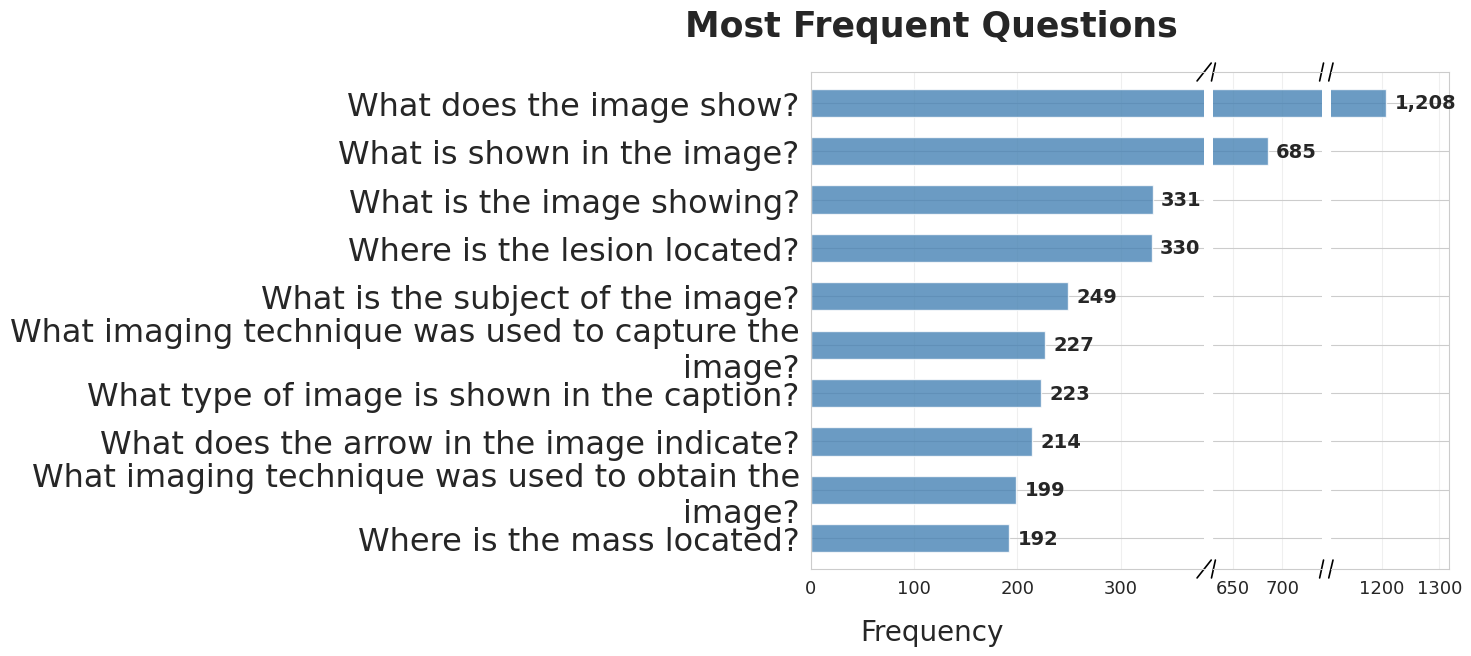

In [9]:
# ============================================================
# FIGURE 4: MOST FREQUENT QUESTIONS
# WITH TWO X-AXIS BREAKS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import textwrap

# Normalize the questions
questions = (
    df['Question']
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.replace(r'\s+([?.!,;:])', r'\1', regex=True)
)

questions = questions[questions != '']

# Get the ten most frequent questions
top_questions = (
    questions
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

values = top_questions.values

if len(values) < 3:
    raise ValueError(
        'At least three questions are required to create two breaks.'
    )

# Split long questions into two lines
labels = [
    textwrap.fill(
        question.capitalize(),
        width=47
    )
    for question in top_questions.index
]

# Close positions between the bars
positions = np.arange(len(top_questions)) * 0.55

# Three highest frequencies
highest = values[-1]
second = values[-2]
third = values[-3]

# Limits of the three segments
left_end = third * 1.15
center_start = second * 0.92
center_end = second * 1.08
right_start = highest * 0.92
right_end = highest * 1.09

# Create three axes that share the Y-axis
fig, (left_ax, center_ax, right_ax) = plt.subplots(
    1, 3,
    sharey=True,
    figsize=(11, 7),
    gridspec_kw={
        'width_ratios': [4, 1.1, 1.2],
        'wspace': 0.045
    }
)

axes = (left_ax, center_ax, right_ax)

# Draw the bars in the three segments
for ax in axes:

    ax.barh(
        positions,
        values,
        height=0.32,
        color='steelblue',
        alpha=0.8
    )

    ax.set_axisbelow(True)

    ax.grid(
        axis='x',
        alpha=0.3
    )

    ax.tick_params(
        axis='x',
        labelsize=13
    )

# Limits of each segment
left_ax.set_xlim(
    0,
    left_end
)

center_ax.set_xlim(
    center_start,
    center_end
)

right_ax.set_xlim(
    right_start,
    right_end
)

# Y-axis labels
left_ax.set_yticks(positions)

left_ax.set_yticklabels(
    labels,
    fontsize=23
)

left_ax.tick_params(
    axis='y',
    length=0,
    pad=8
)

# Hide the Y-axis labels on the center and right panels
center_ax.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

right_ax.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

# Adjust the vertical range
left_ax.set_ylim(
    positions[0] - 0.35,
    positions[-1] + 0.35
)

# Hide the borders where the breaks occur
left_ax.spines['right'].set_visible(False)

center_ax.spines['left'].set_visible(False)
center_ax.spines['right'].set_visible(False)

right_ax.spines['left'].set_visible(False)

# Diagonal break marks
mark = 0.018

mark_style = {
    'color': 'black',
    'linewidth': 1.2,
    'clip_on': False
}

for y in (0, 1):

    # Break between the left and center axes
    left_ax.plot(
        (1 - mark, 1 + mark),
        (y - mark, y + mark),
        transform=left_ax.transAxes,
        **mark_style
    )

    center_ax.plot(
        (-mark, mark),
        (y - mark, y + mark),
        transform=center_ax.transAxes,
        **mark_style
    )

    # Break between the center and right axes
    center_ax.plot(
        (1 - mark, 1 + mark),
        (y - mark, y + mark),
        transform=center_ax.transAxes,
        **mark_style
    )

    right_ax.plot(
        (-mark, mark),
        (y - mark, y + mark),
        transform=right_ax.transAxes,
        **mark_style
    )

# Place each frequency in the segment where its bar ends
for position, value in zip(positions, values):

    if value > center_end:
        axis = right_ax
    elif value > left_end:
        axis = center_ax
    else:
        axis = left_ax

    axis.annotate(
        f'{value:,}',
        xy=(value, position),
        xytext=(6, 0),
        textcoords='offset points',
        va='center',
        ha='left',
        fontsize=14,
        fontweight='bold'
    )

# Title
fig.suptitle(
    'Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    y=0.96
)

# Overall X-axis label
fig.supxlabel(
    'Frequency',
    fontsize=20,
    y=0.05
)

# Adjust margins
plt.subplots_adjust(
    left=0.39,
    right=0.97,
    top=0.87,
    bottom=0.16
)

plt.show()

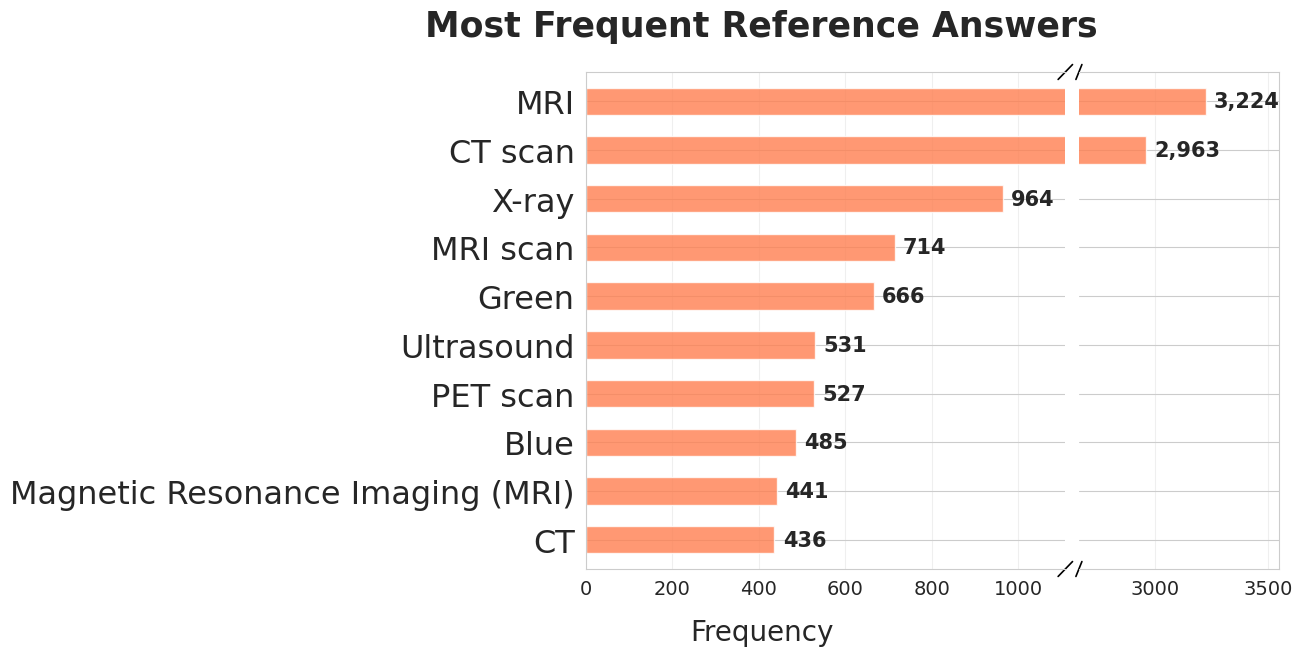

In [10]:
# ============================================================
# FIGURE 5: MOST FREQUENT REFERENCE ANSWERS
# WITH BROKEN X-AXIS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Normalize the answers
answers = (
    df['ground_truth']
    .dropna()
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

answers = answers[answers != '']

# Get the ten most frequent answers
top_answers = (
    answers
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

values = top_answers.values

if len(values) < 3:
    raise ValueError(
        'At least three answers are required to create the break.'
    )

# Shorten only excessively long answers
labels = [
    answer if len(answer) <= 55
    else answer[:52] + '...'
    for answer in top_answers.index
]

# Bar positions
positions = np.arange(len(top_answers)) * 0.50

# Three highest frequencies
highest = values[-1]
second = values[-2]
third = values[-3]

# Place the break between the third- and second-highest frequencies
left_limit = third * 1.15
right_limit = second * 0.90

# Create two panels that share the Y-axis
fig, (left_ax, right_ax) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(11, 7),
    gridspec_kw={
        'width_ratios': [3, 1.25],
        'wspace': 0.04
    }
)

# Draw the bars in both panels
for ax in (left_ax, right_ax):

    ax.barh(
        positions,
        values,
        height=0.28,
        color='coral',
        alpha=0.8
    )

    ax.set_axisbelow(True)

    ax.grid(
        axis='x',
        alpha=0.3
    )

    ax.tick_params(
        axis='x',
        labelsize=14
    )

# Limits before and after the break
left_ax.set_xlim(
    0,
    left_limit
)

right_ax.set_xlim(
    right_limit,
    highest * 1.10
)

# Y-axis labels
left_ax.set_yticks(positions)

left_ax.set_yticklabels(
    labels,
    fontsize=23
)

left_ax.tick_params(
    axis='y',
    length=0,
    pad=8
)

# Hide Y-axis labels on the right panel
right_ax.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

# Adjust the vertical space
left_ax.set_ylim(
    positions[0] - 0.30,
    positions[-1] + 0.30
)

# Hide the inner borders
left_ax.spines['right'].set_visible(False)
right_ax.spines['left'].set_visible(False)

# Diagonal marks to indicate the break
mark = 0.015

mark_style = {
    'color': 'black',
    'linewidth': 1.2,
    'clip_on': False
}

for y in (0, 1):

    left_ax.plot(
        (1 - mark, 1 + mark),
        (y - mark, y + mark),
        transform=left_ax.transAxes,
        **mark_style
    )

    right_ax.plot(
        (-mark, mark),
        (y - mark, y + mark),
        transform=right_ax.transAxes,
        **mark_style
    )

# Display the frequencies at the end of the bars
for position, value in zip(positions, values):

    # The two highest frequencies end in the right panel
    axis = right_ax if value > left_limit else left_ax

    axis.annotate(
        f'{value:,}',
        xy=(value, position),
        xytext=(6, 0),
        textcoords='offset points',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

# Overall title
fig.suptitle(
    'Most Frequent Reference Answers',
    fontsize=25,
    fontweight='bold',
    y=0.96
)

# Overall X-axis label
fig.supxlabel(
    'Frequency',
    fontsize=20,
    y=0.05
)

# Adjust margins
plt.subplots_adjust(
    left=0.34,
    right=0.97,
    top=0.87,
    bottom=0.16
)

plt.show()

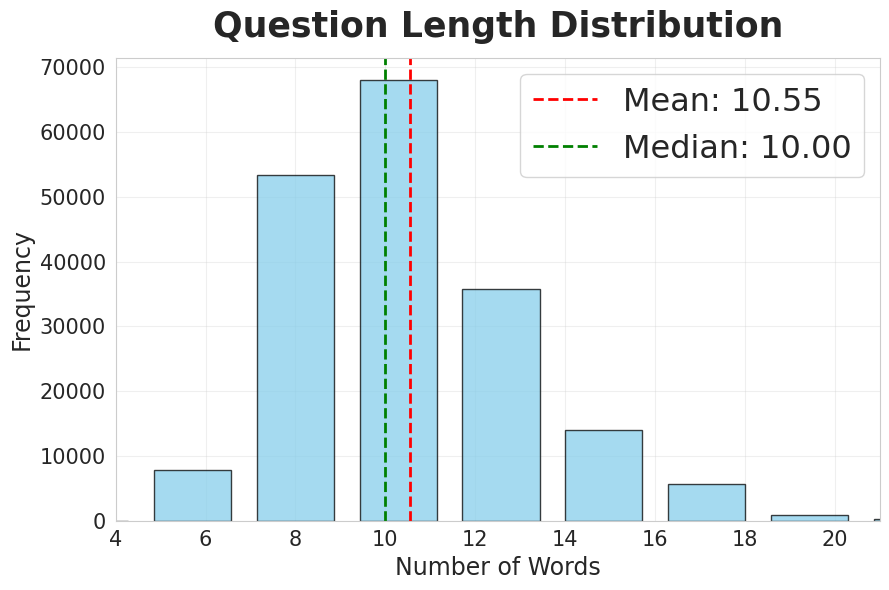

In [11]:
# ============================================================
# FIGURE 6: QUESTION LENGTH DISTRIBUTION
# ============================================================

# Calculate the number of words if the column does not yet exist
if 'question_words' not in df.columns:
    df['question_words'] = (
        df['Question']
        .fillna('')
        .astype(str)
        .str.split()
        .str.len()
    )

mean = df['question_words'].mean()
median = df['question_words'].median()

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df['question_words'],
    bins=21,
    color='skyblue',
    edgecolor='black',
    alpha=0.75,
    rwidth=0.75,  # Controls the bar thickness
)

ax.axvline(
    mean,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean: {mean:.2f}'
)

ax.axvline(
    median,
    color='green',
    linestyle='--',
    linewidth=2,
    label=f'Median: {median:.2f}'
)

ax.set_xlim(4, 21)
ax.set_xlabel('Number of Words', fontsize=17)
ax.set_ylabel('Frequency', fontsize=17)

ax.set_title(
    'Question Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=15
)



ax.tick_params(axis='both', labelsize=15)
ax.legend(fontsize=23)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

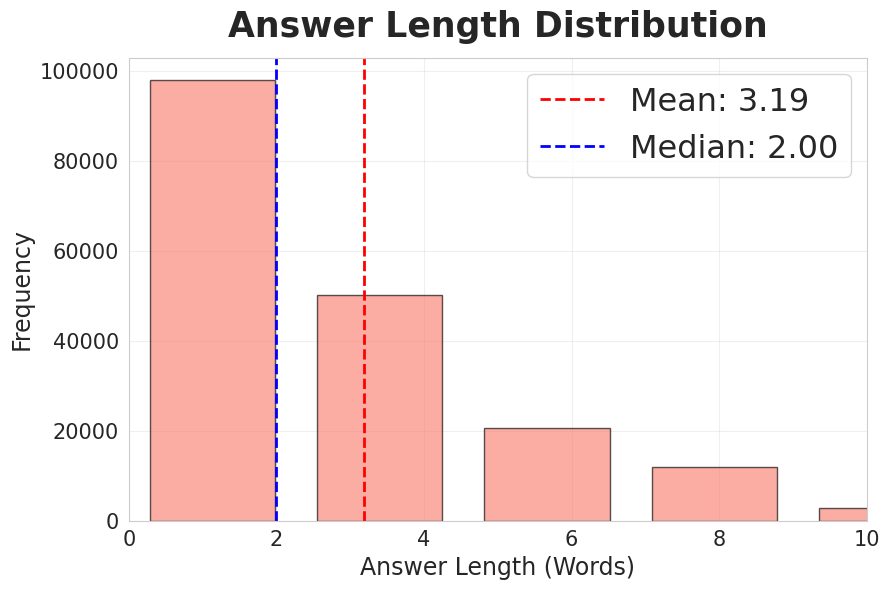

In [12]:
# ============================================================
# FIGURE 7: QUESTION LENGTH DISTRIBUTION
# ============================================================

ground_truth_words = (
    df['ground_truth']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.split()
    .str.len()
)

mean = ground_truth_words.mean()
median = ground_truth_words.median()

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    ground_truth_words,
    bins=15,
    color='salmon',
    edgecolor='black',
    alpha=0.65,
    rwidth=0.75  # Controls the bar thickness
)

ax.axvline(
    mean,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean: {mean:.2f}'
)

ax.axvline(
    median,
    color='blue',
    linestyle='--',
    linewidth=2,
    label=f'Median: {median:.2f}'
)

ax.set_xlim(0, 10)
ax.set_xlabel('Answer Length (Words)', fontsize=17)
ax.set_ylabel('Frequency', fontsize=17)

ax.set_title(
    'Answer Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=15
)

ax.tick_params(axis='both', labelsize=15)
ax.legend(fontsize=23)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()